# Lagrangian turbulence, M = 1024: does the number of scales J change which statistics are reproduced?
**Question.** Models with J = 8, 9, 10 scales (with and without the coarse Q=3 channels) all match their imposed moments; do they also reproduce the statistics they do not impose: power spectrum, structure functions, cross-scale correlations, wavelet bands, Scat4?
**Method.** `turbulence/cross_scale_compare.py` (launcher `turbulence/launch/compare_scat34.sh`, seed 900) computes each statistic on the data and on each model's final samples; a point is reproduced when it lies within ±2σ of the data.
**Result.** (to fill once all runs are in)

Runs (model = B + Scat3 Re/Im + Scat4 diag, n1 = 5000, nt = 27500 + terminal phase, σ = 2.5):
- `J9` = ..._scat34d_term_lagr1024J9 (all Q=3 channels imposed);
- `J9_cut`, `J8_cut`, `J10_cut` = ..._lagr1024J<J>_q3cut (Q=3 channels ≥ 13, periods > 32 samples, not imposed).

**How to read the bands.** Grey = data ± 2σ, σ = data sampling noise (random halves of the data) + run-to-run noise (spread over the 3 seeds of `J9`, assumed to hold for the other runs too). Lags τ are in samples of the original signal (M = 1024 has no coarse graining), so they are not the same physical lags as in the M = 256 notebooks (there 1 sample = 2 original samples).

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
OUT = Path('figures/cross_scale_m1024')   # relative to turbulence/
assert (OUT / 'summary.csv').exists(), 'run turbulence/launch/compare_scat34.sh (OUT_CS=turbulence/figures/cross_scale_m1024) first'

## Summary: fraction of points within 2σ of the data, per statistic family
1 = reproduced everywhere.

run,J8_cut,J9,J9_cut
family,,,
C_pq at tau*=20 (paper),0.82,0.84,0.20
C_pq maps (all lag pairs),0.83,0.89,0.61
Scat4 statistics,0.91,1.00,1.00
burst persistence,0.02,0.11,0.02
extremes per signal,0.67,0.83,0.58
flatness slope,0.77,0.92,0.62
increment PDFs,0.56,0.52,0.69
marginal,0.67,0.70,0.47
scaling ratio zeta4/zeta2,0.69,0.92,0.73


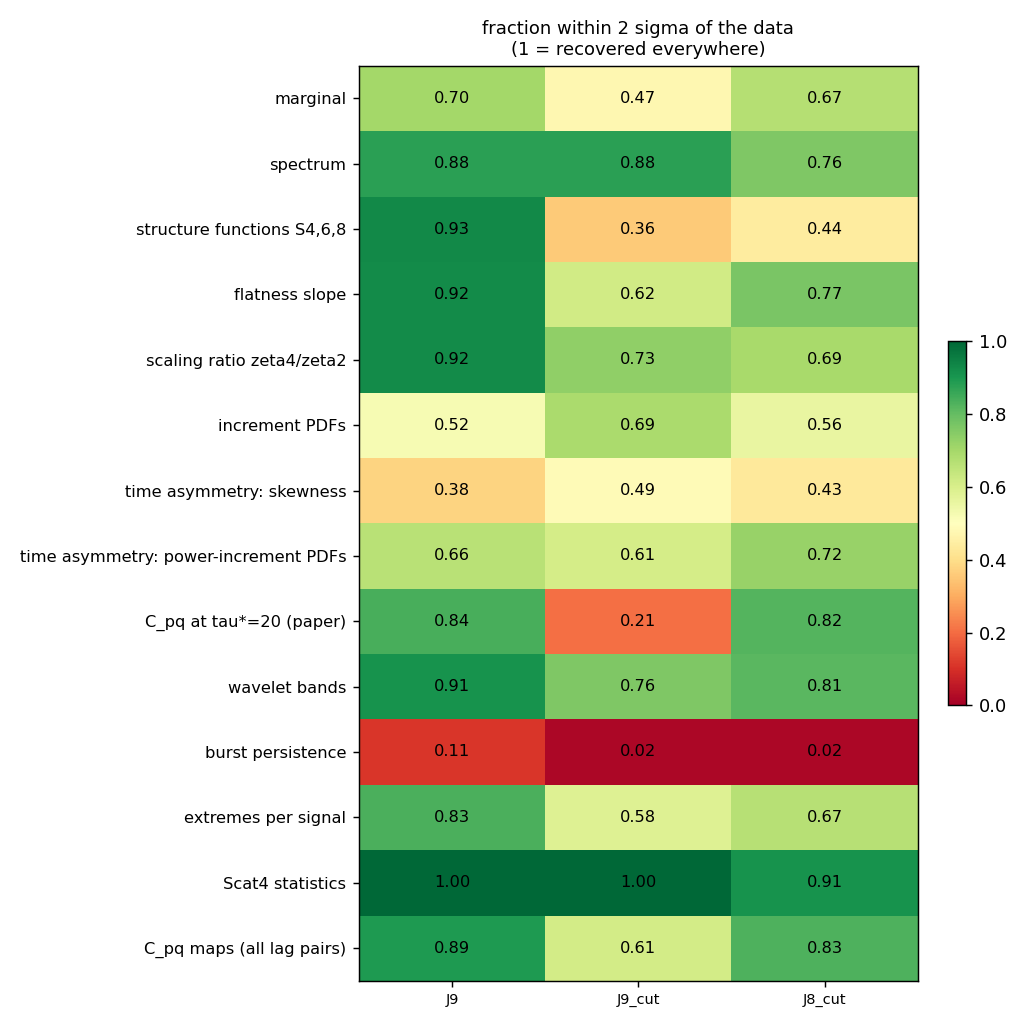

In [2]:
S = pd.read_csv(OUT / 'summary.csv')
display(S.pivot(index='family', columns='run', values='frac_within_2sigma').round(2))
display(Image(OUT / 'summary.png'))

## Cross-scale statistics
C_pq(τ*, τ) = ⟨|δ_τ* x|^p |δ_τ x|^q⟩ / (S_p(τ*) S_q(τ)), with δ_τ x the increment over τ samples and S_p the structure function of order p: how often large increments at one scale come together with large increments at another, at the same time. (2,2) = C4, (3,3) = C6, (4,2) = C42, plus (4,4) and (3,1). First the curves and 1-D cuts, then the full maps as log(model / data) (white = match).

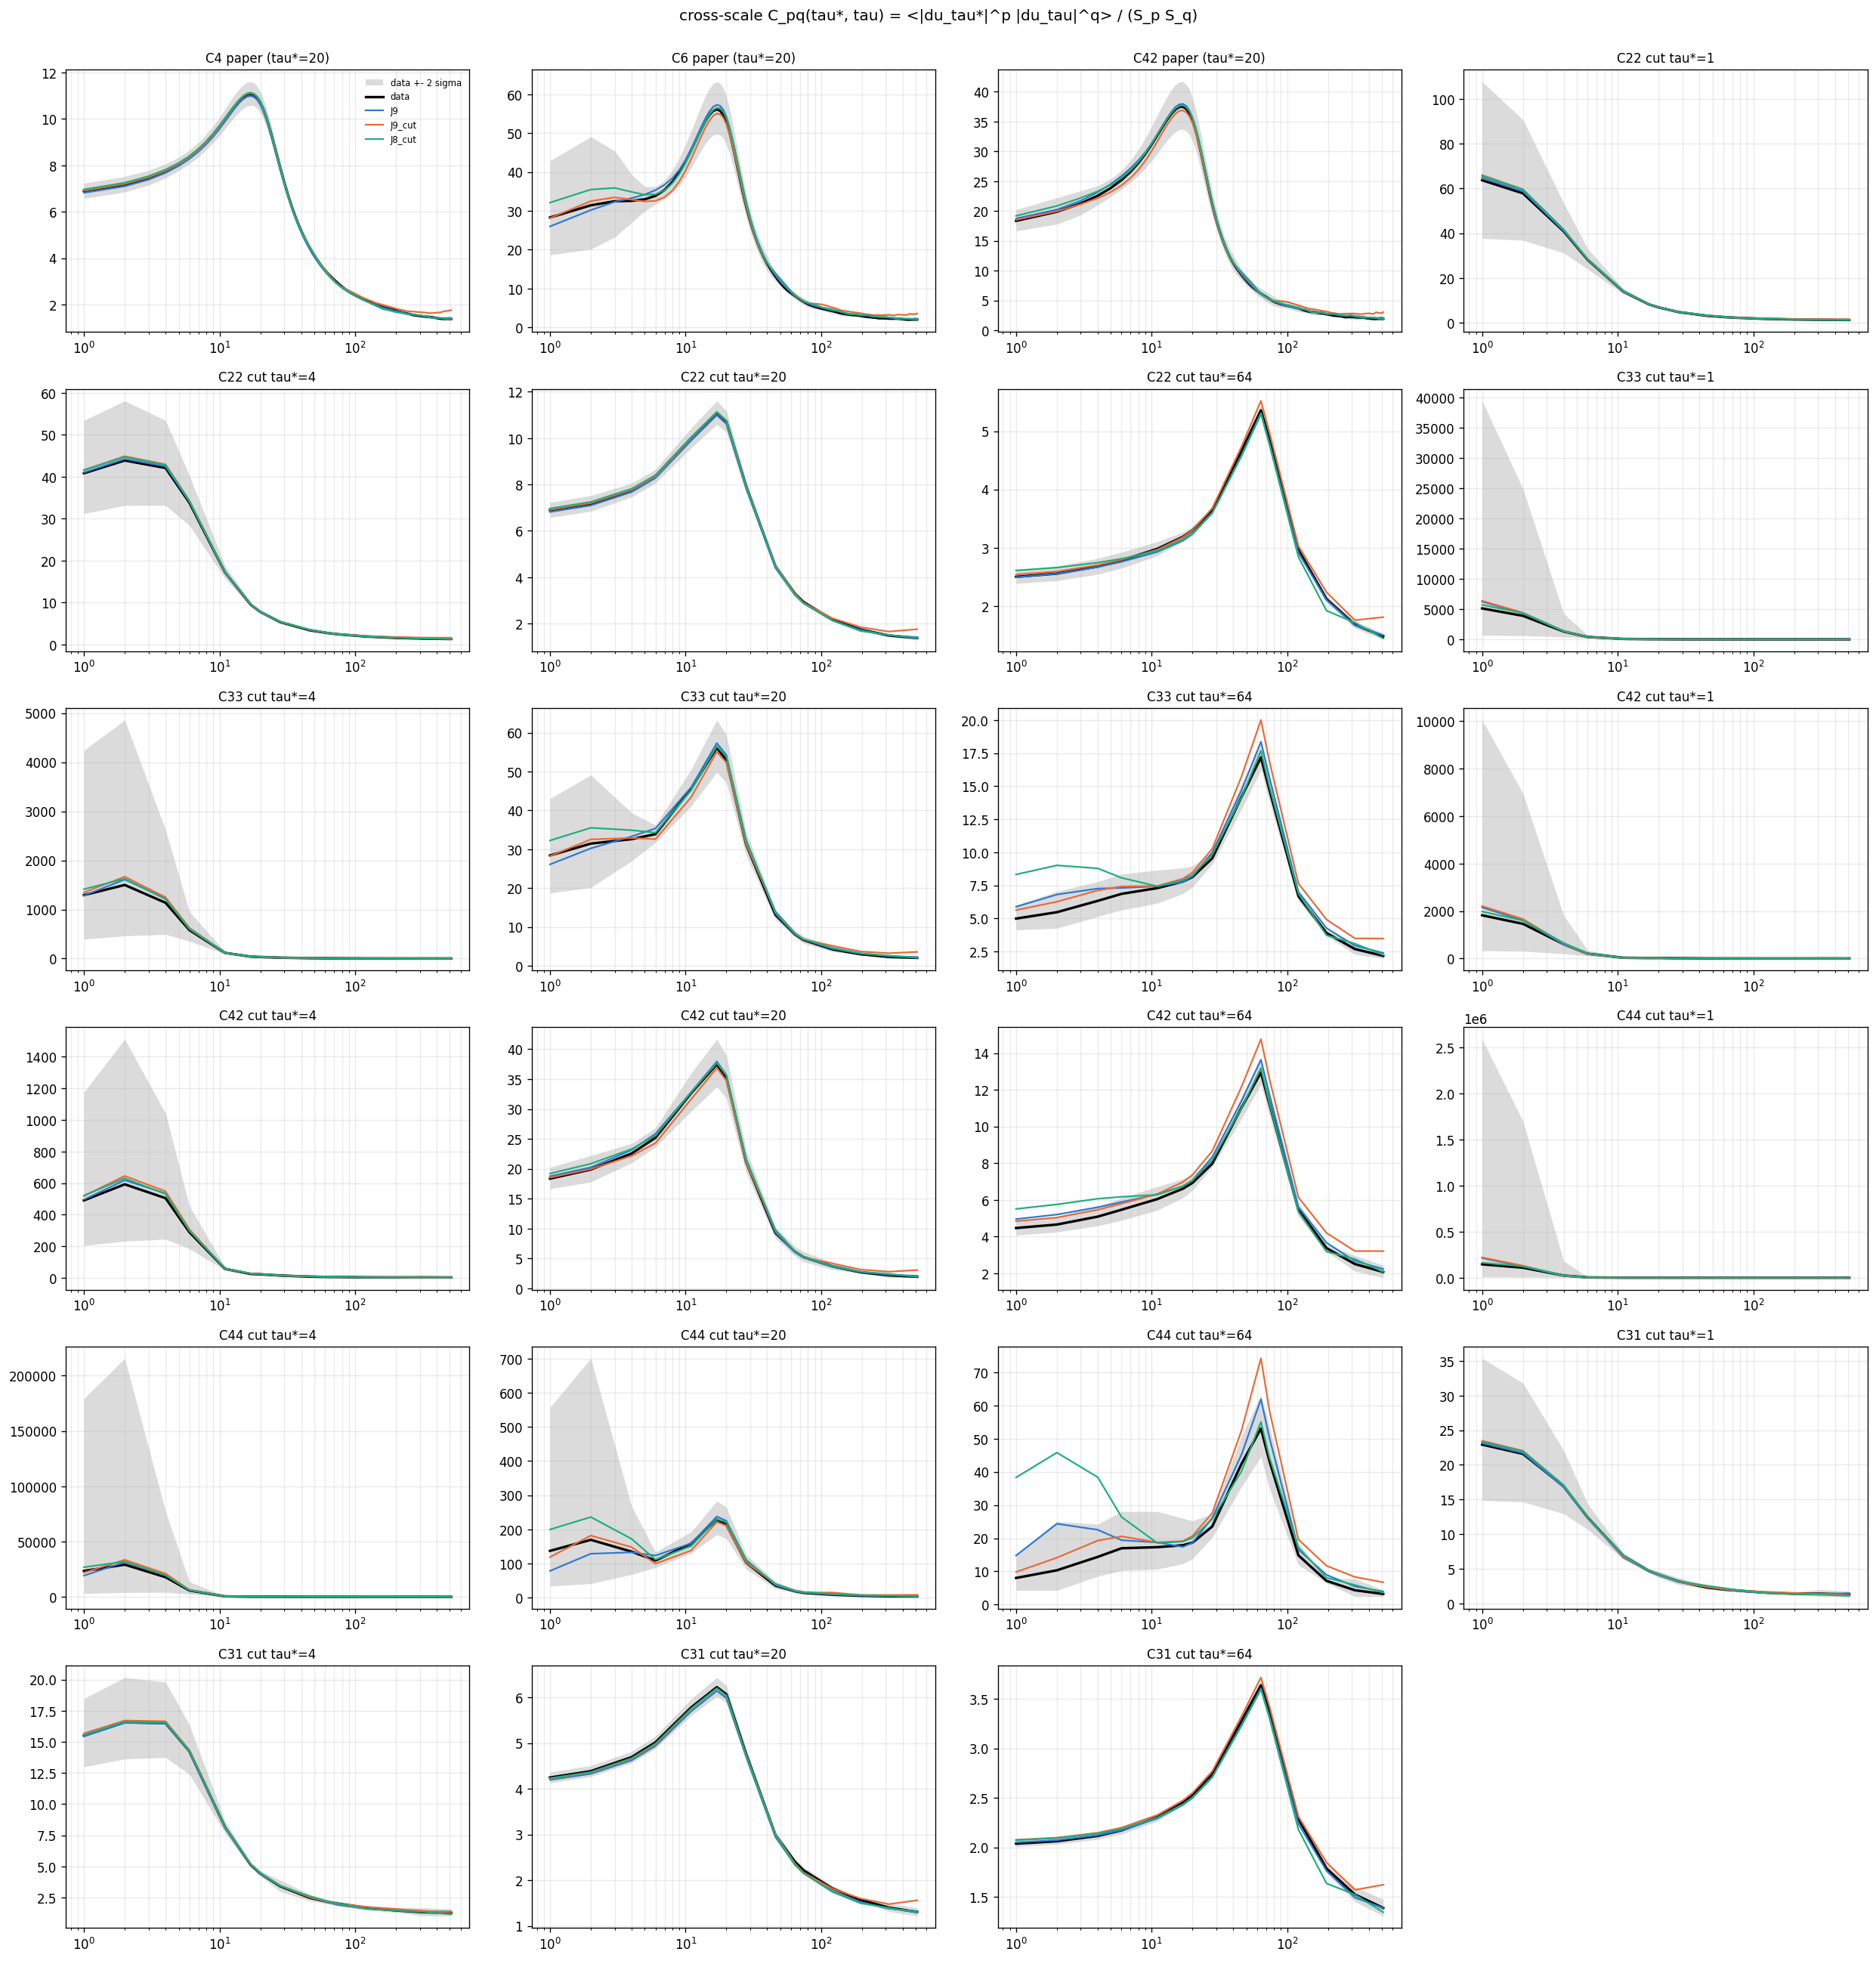

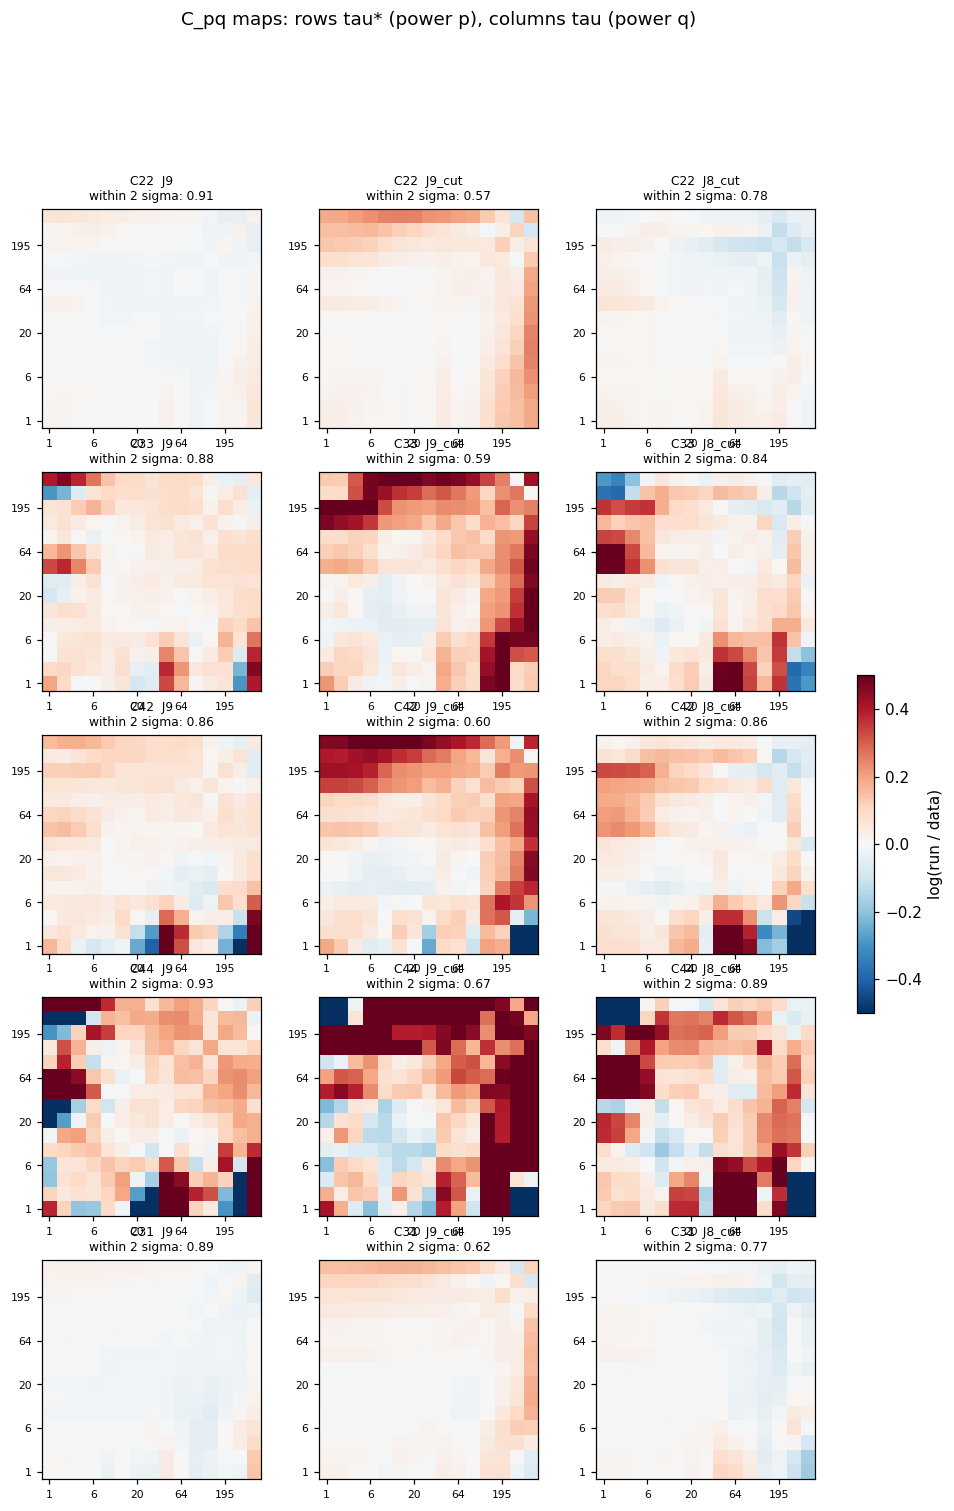

In [3]:
display(Image(OUT / 'cross_scale_cuts.png'))
display(Image(OUT / 'cross_scale_maps.png'))

## Bursts in time and extremes per signal
Burst persistence: correlation between the log-size of an increment now and D samples later (a cascade keeps it high over long D). Extremes: quantiles of the largest increment of each signal, in units of the data's standard deviation σ_τ at that lag.

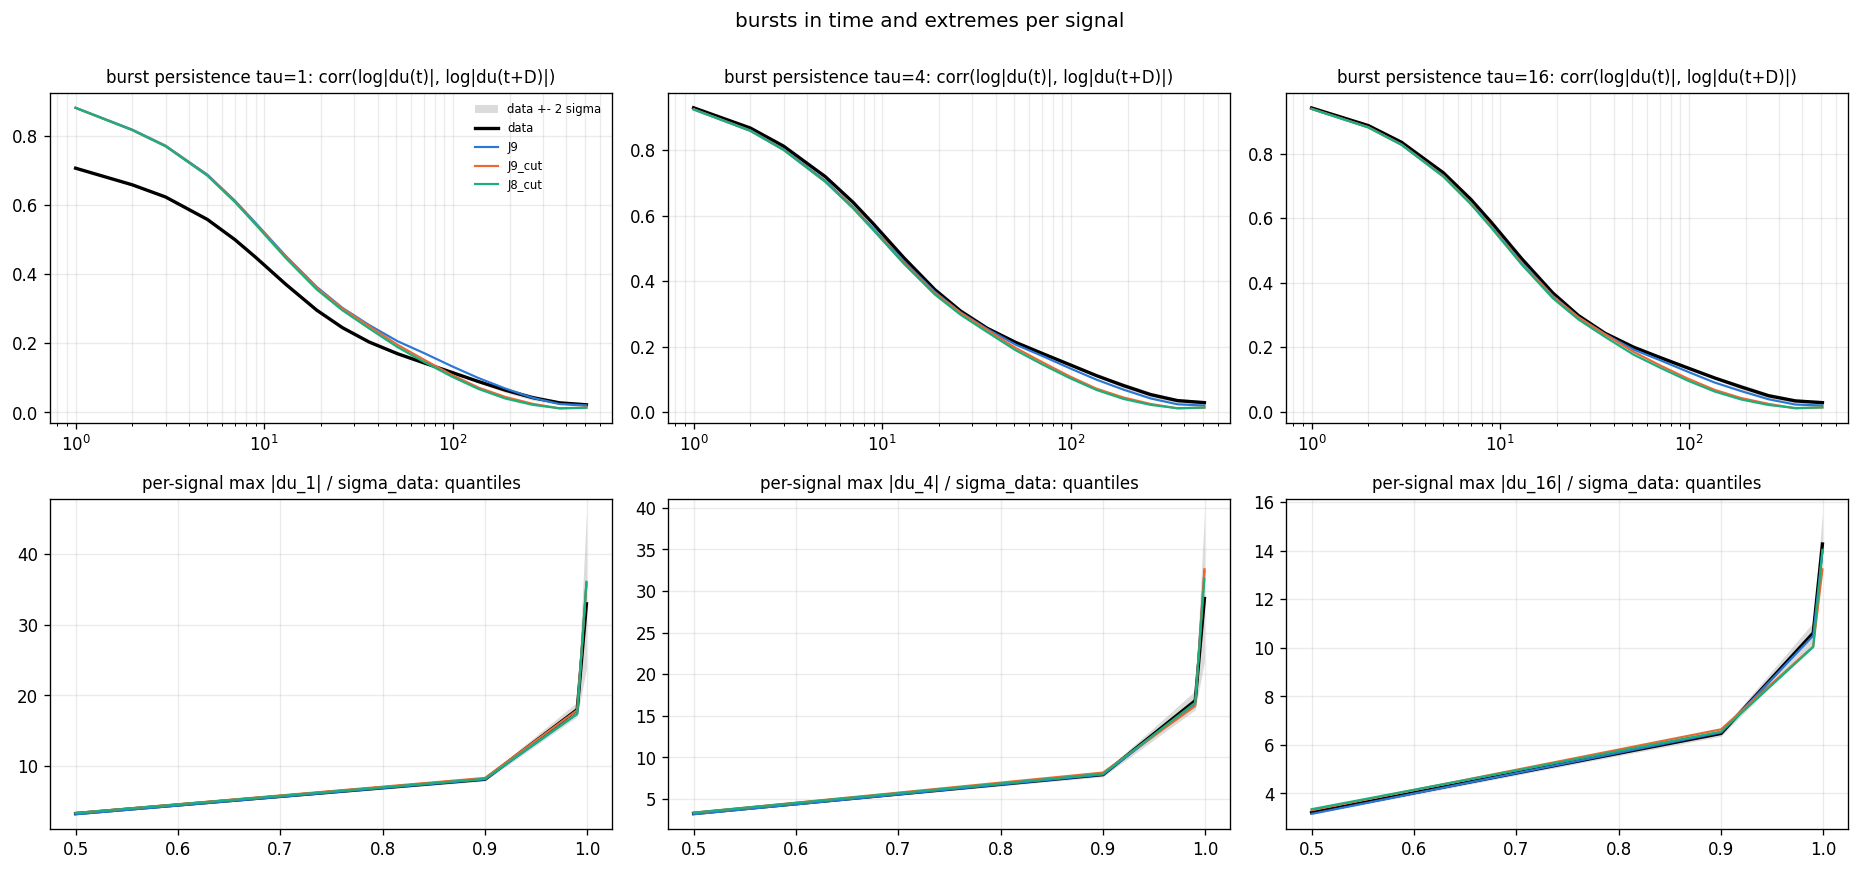

In [4]:
display(Image(OUT / 'persistence_extremes.png'))

## Scat4 statistics and wavelet bands
Scat4 = fourth-order scattering statistics (products of wavelet-modulus envelopes at two scales). Panels: (model − data)/σ for every Scat4 statistic, outside ±2 = not reproduced. They are computed with the scales J of the first run in the launcher's `LABELS`, so a model with fewer scales is tested here on scales it does not impose.

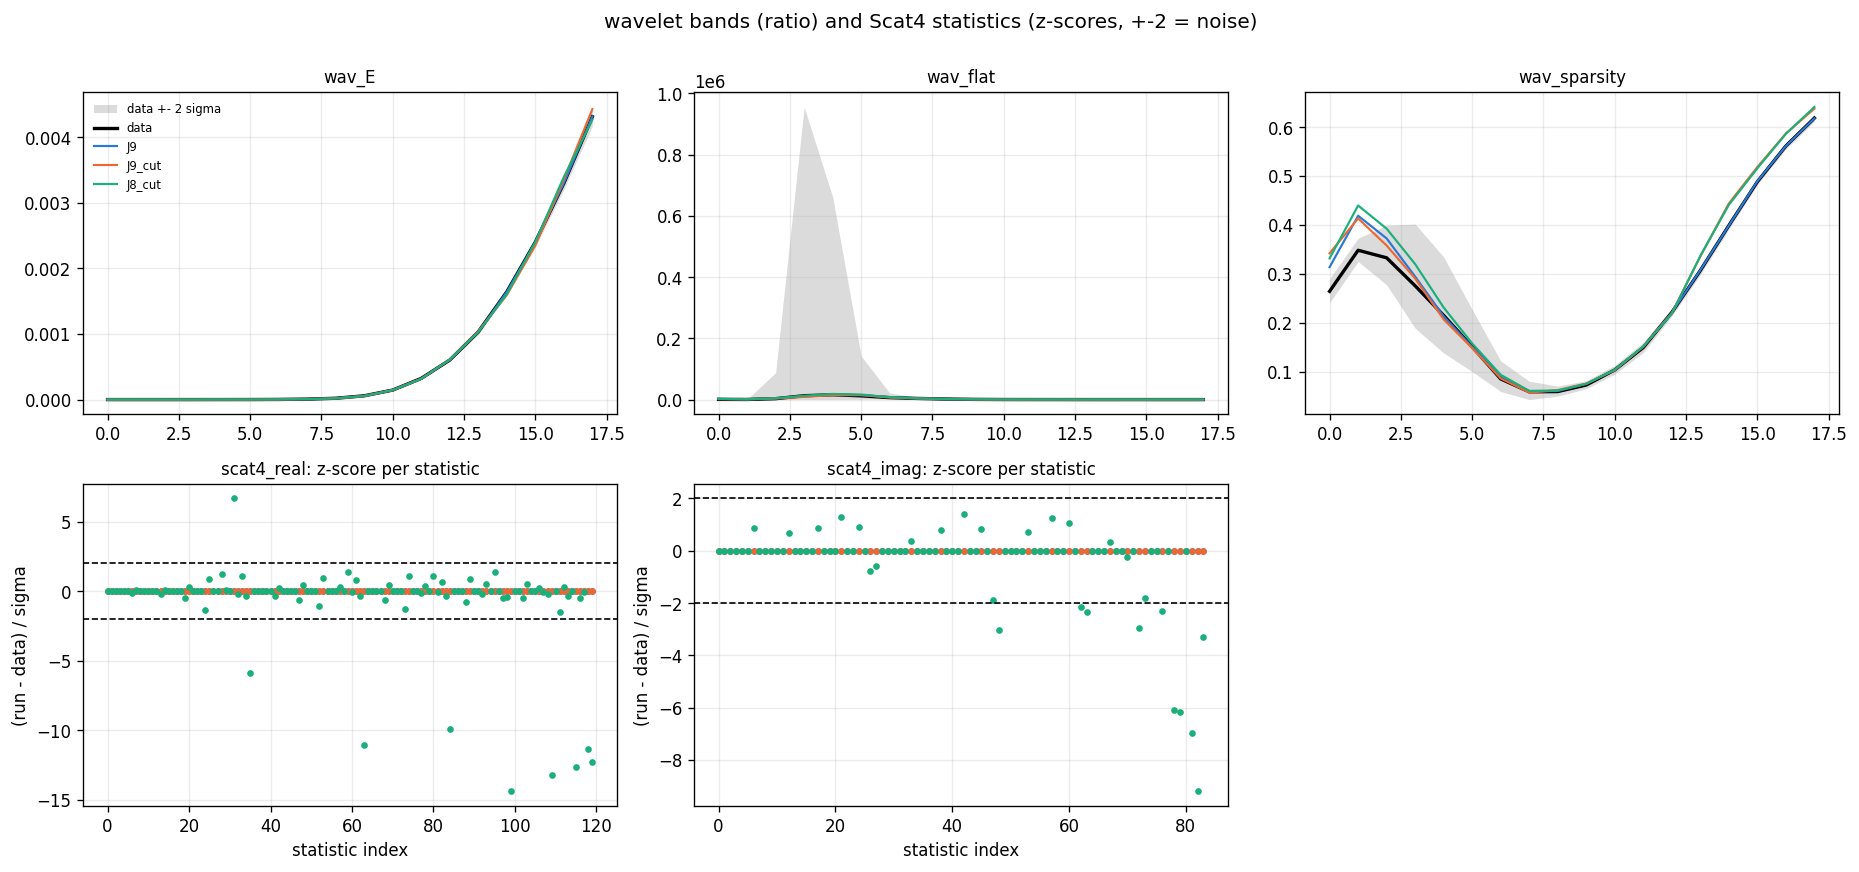

In [5]:
display(Image(OUT / 'wavelet_scat4.png'))

## Single-scale statistics and PDFs
Marginal PDF, power spectrum, structure functions, flatness, increment PDFs, skewness of the power increments.

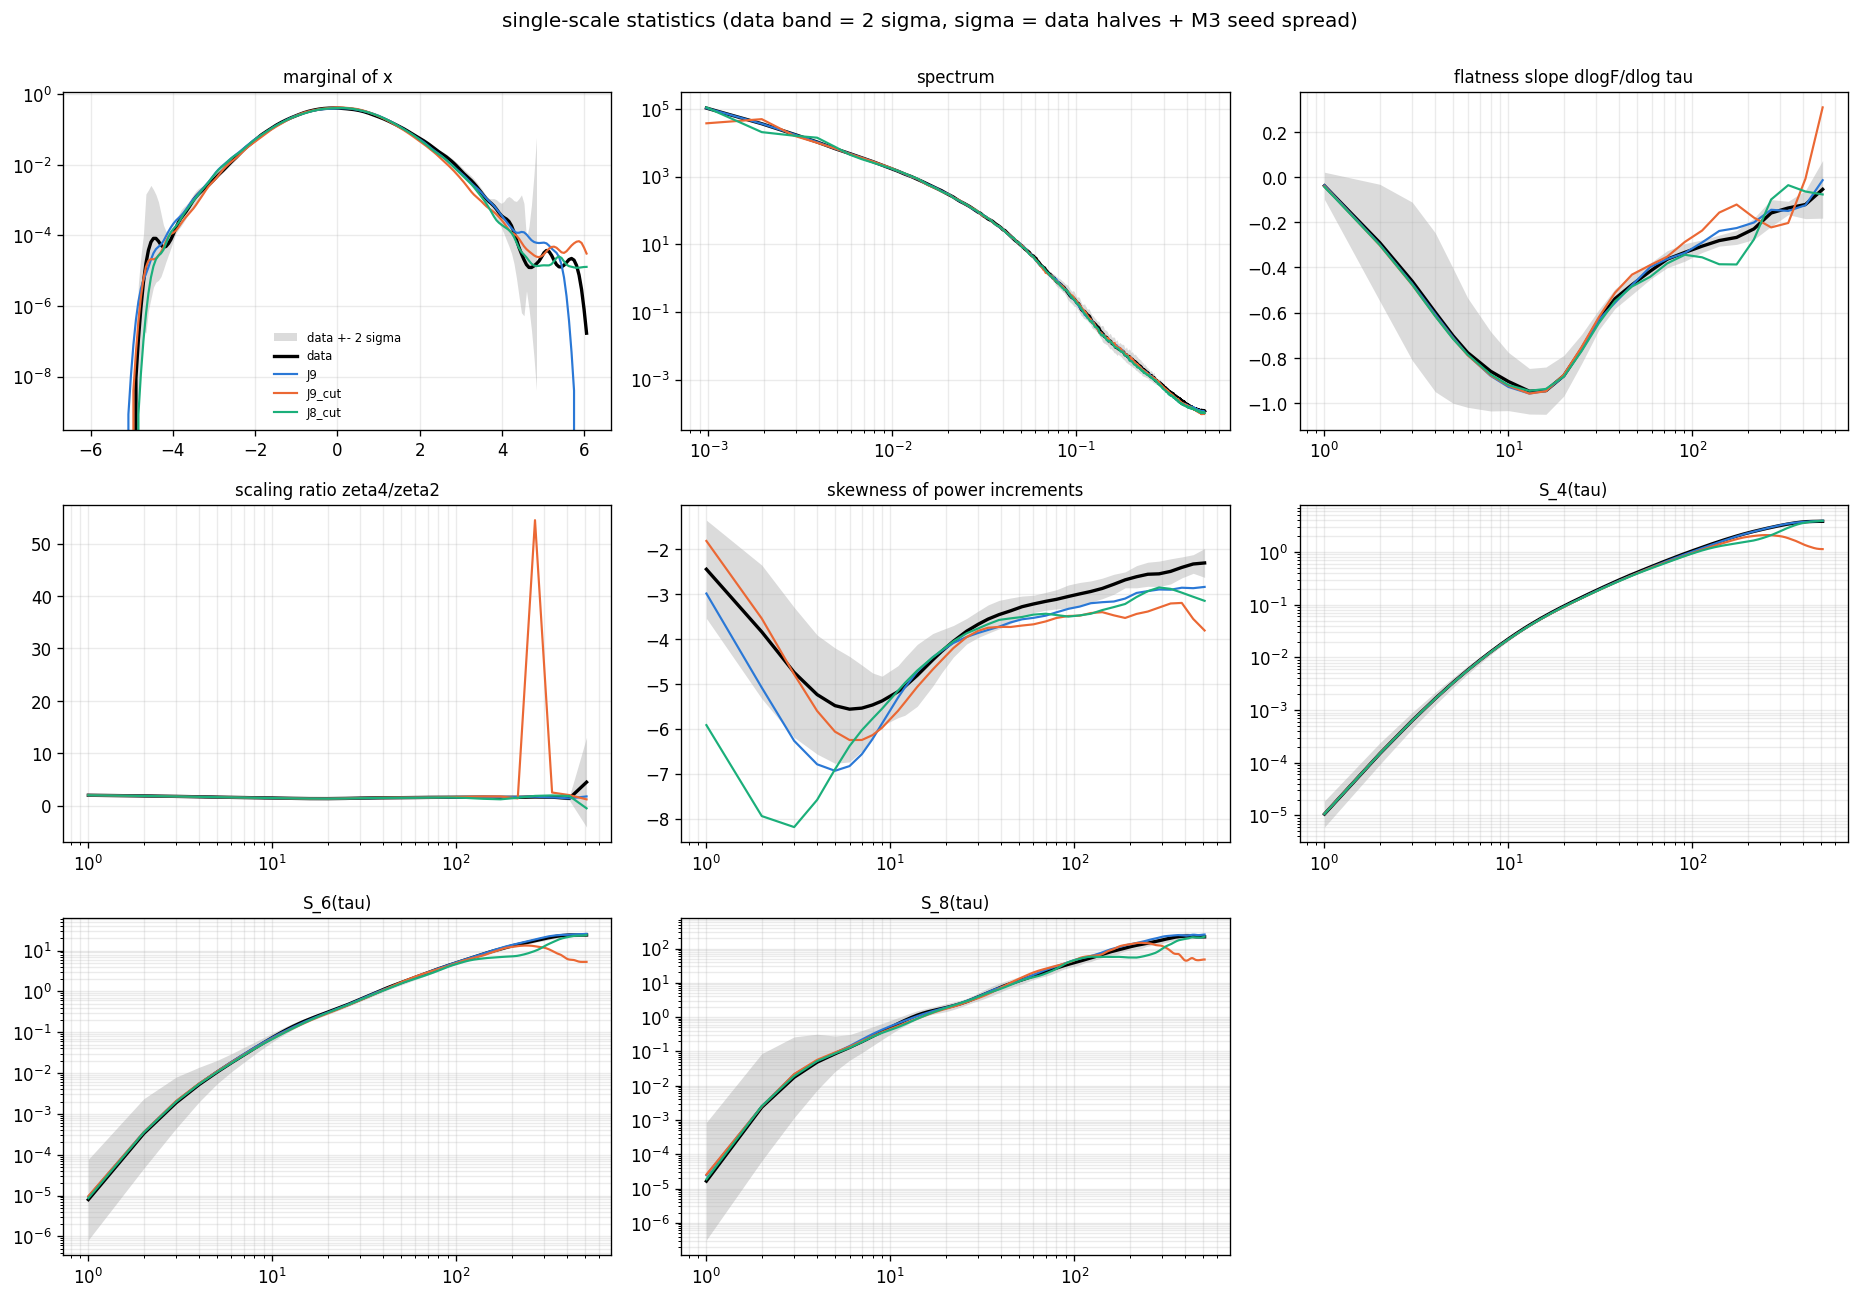

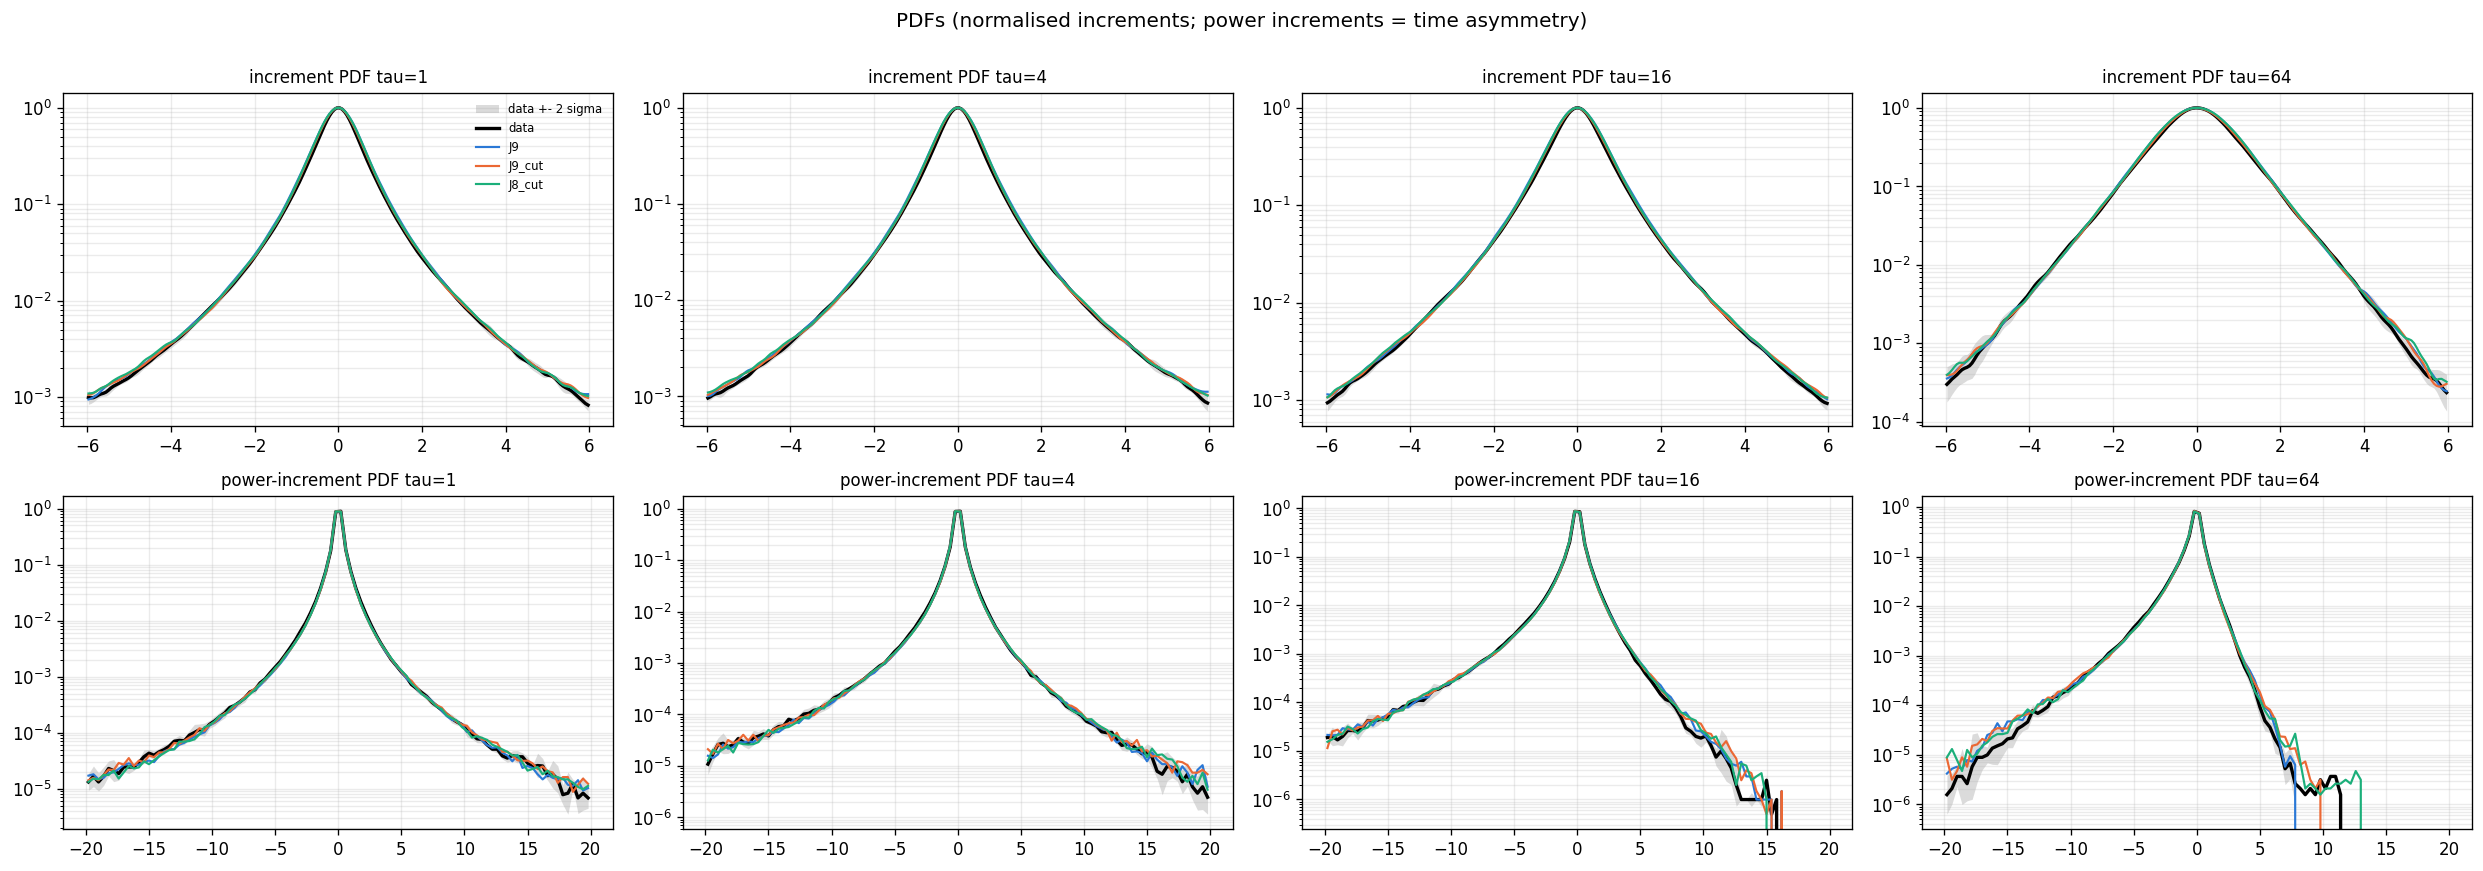

In [6]:
display(Image(OUT / 'single_scale.png'))
display(Image(OUT / 'pdfs.png'))